<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/07_Recommendation_Systems/notebooks/05_Content_Based_Movie_Recommendation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 33: Content-Based Movie Recommendation System

## Objective
Build a movie recommendation system using movie metadata.

## Techniques
- Content-Based Filtering
- Text Preprocessing
- TF-IDF Vectorization
- Cosine Similarity
- User Preference Profiles
- Top-N Recommendations

## Dataset
MovieLens Latest Small

## Libraries
Python, Pandas, NumPy, Scikit-learn

In [1]:
#Import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel

import zipfile
import urllib.request
import os

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
#Load the MovieLens dataset
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

if not os.path.exists("ml-latest-small"):
    urllib.request.urlretrieve(url, "movielens.zip")

    with zipfile.ZipFile("movielens.zip", "r") as zip_ref:
        zip_ref.extractall(".")

movies = pd.read_csv("ml-latest-small/movies.csv")
ratings = pd.read_csv("ml-latest-small/ratings.csv")

print("Movies:", movies.shape)
print("Ratings:", ratings.shape)

display(movies.head())

Movies: (9742, 3)
Ratings: (100836, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
#Inspect movie metadata
print("Movie columns:")
print(movies.columns.tolist())

print("\nMissing values:")
print(movies.isnull().sum())

print("\nGenre examples:")
display(movies[["title", "genres"]].head(10))

Movie columns:
['movieId', 'title', 'genres']

Missing values:
movieId    0
title      0
genres     0
dtype: int64

Genre examples:


,title,genres
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,Jumanji (1995),Adventure|Children|Fantasy
2,Grumpier Old Men (1995),Comedy|Romance
3,Waiting to Exhale (1995),Comedy|Drama|Romance
4,Father of the Bride Part II (1995),Comedy
5,Heat (1995),Action|Crime|Thriller
6,Sabrina (1995),Comedy|Romance
7,Tom and Huck (1995),Adventure|Children
8,Sudden Death (1995),Action
9,GoldenEye (1995),Action|Adventure|Thriller


,count
genres,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


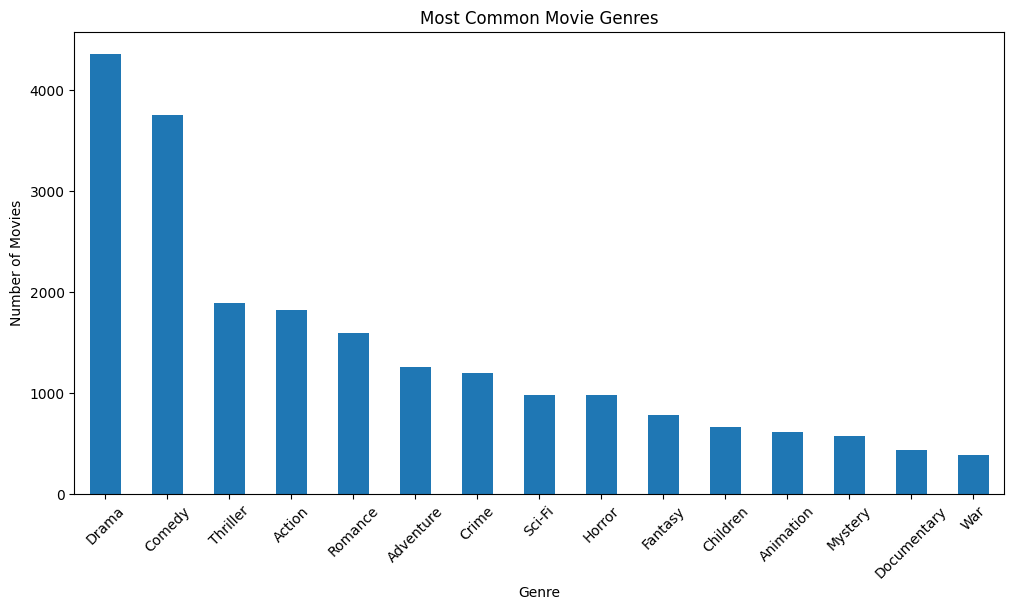

In [4]:
#Explore movie genres
all_genres = (
    movies["genres"]
    .str.split("|")
    .explode()
)

genre_counts = all_genres.value_counts()

display(genre_counts.head(20))

plt.figure(figsize=(12, 6))

genre_counts.drop("IMAX", errors="ignore").head(15).plot(
    kind="bar"
)

plt.title("Most Common Movie Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

In [5]:
#Clean the genres
movies["genres_clean"] = (
    movies["genres"]
    .replace("(no genres listed)", "")
    .fillna("")
)

display(
    movies[["title", "genres", "genres_clean"]].head(10)
)

,title,genres,genres_clean
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Adventure|Animation|Children|Comedy|Fantasy
1,Jumanji (1995),Adventure|Children|Fantasy,Adventure|Children|Fantasy
2,Grumpier Old Men (1995),Comedy|Romance,Comedy|Romance
3,Waiting to Exhale (1995),Comedy|Drama|Romance,Comedy|Drama|Romance
4,Father of the Bride Part II (1995),Comedy,Comedy
5,Heat (1995),Action|Crime|Thriller,Action|Crime|Thriller
6,Sabrina (1995),Comedy|Romance,Comedy|Romance
7,Tom and Huck (1995),Adventure|Children,Adventure|Children
8,Sudden Death (1995),Action,Action
9,GoldenEye (1995),Action|Adventure|Thriller,Action|Adventure|Thriller


In [6]:
#Apply TF-IDF
tfidf = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

tfidf_matrix = tfidf.fit_transform(
    movies["genres_clean"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of genre features:", len(tfidf.get_feature_names_out()))

print("\nGenre vocabulary:")
print(tfidf.get_feature_names_out())

TF-IDF matrix shape: (9742, 21)
Number of genre features: 21

Genre vocabulary:
['action' 'adventure' 'animation' 'children' 'comedy' 'crime'
 'documentary' 'drama' 'fantasy' 'fi' 'film' 'horror' 'imax' 'musical'
 'mystery' 'noir' 'romance' 'sci' 'thriller' 'war' 'western']


In [7]:
#Create the recommendation function
def recommend_similar_movies(movie_title, top_n=10):

    # Find the movie by its title
    matching_movies = movies[
        movies["title"].str.lower() == movie_title.lower()
    ]

    if matching_movies.empty:
        print("Movie not found.")
        return pd.DataFrame()

    # Get the index of the selected movie
    movie_index = matching_movies.index[0]

    # Calculate similarity against all movie vectors
    similarity_scores = linear_kernel(
        tfidf_matrix[movie_index],
        tfidf_matrix
    ).flatten()

    # Get the top similar movie indices
    similar_indices = similarity_scores.argsort()[::-1]

    # Remove the selected movie itself
    similar_indices = [
        index for index in similar_indices
        if index != movie_index
    ]

    # Select top N results
    top_indices = similar_indices[:top_n]

    results = movies.iloc[top_indices][
        ["title", "genres"]
    ].copy()

    results["similarity"] = similarity_scores[top_indices]

    return results.reset_index(drop=True)

In [8]:
#Test the recommendation engine
recommendations = recommend_similar_movies(
    "Toy Story (1995)",
    top_n=10
)

display(recommendations)

display(
    recommend_similar_movies(
        "Jumanji (1995)",
        top_n=10
    )
)

,title,genres,similarity
0,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
2,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
4,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,1.0
5,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
6,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0
7,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
8,The Good Dinosaur (2015),Adventure|Animation|Children|Comedy|Fantasy,1.0
9,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0


,title,genres,similarity
0,"NeverEnding Story III, The (1994)",Adventure|Children|Fantasy,1.0
1,"Indian in the Cupboard, The (1995)",Adventure|Children|Fantasy,1.0
2,Seventh Son (2014),Adventure|Children|Fantasy,1.0
3,Escape to Witch Mountain (1975),Adventure|Children|Fantasy,1.0
4,The Cave of the Golden Rose (1991),Adventure|Children|Fantasy,1.0
5,Percy Jackson: Sea of Monsters (2013),Adventure|Children|Fantasy,1.0
6,Chronicles of Narnia: The Voyage of the Dawn T...,Adventure|Children|Fantasy,1.0
7,Alice in Wonderland (1933),Adventure|Children|Fantasy,1.0
8,"Chronicles of Narnia: Prince Caspian, The (2008)",Adventure|Children|Fantasy,1.0
9,"Water Horse: Legend of the Deep, The (2007)",Adventure|Children|Fantasy,1.0


In [9]:
#Split ratings
from sklearn.model_selection import train_test_split

train_ratings, test_ratings = train_test_split(
    ratings,
    test_size=0.20,
    random_state=42
)

print("Training ratings:", train_ratings.shape)
print("Testing ratings:", test_ratings.shape)

Training ratings: (80668, 4)
Testing ratings: (20168, 4)


In [10]:
#Build a user profile
# Create a mapping from movieId to the row position in the TF-IDF matrix
movie_id_to_index = pd.Series(
    movies.index,
    index=movies["movieId"]
).to_dict()


def build_user_profile(user_id, min_rating=4.0):

    # Get the user's training ratings
    user_history = train_ratings[
        train_ratings["userId"] == user_id
    ]

    # Keep only positively rated movies
    liked_movies = user_history[
        user_history["rating"] >= min_rating
    ]

    # Keep movie IDs that exist in our metadata
    liked_movie_ids = [
        movie_id
        for movie_id in liked_movies["movieId"]
        if movie_id in movie_id_to_index
    ]

    if len(liked_movie_ids) == 0:
        return None

    # Find the corresponding TF-IDF row positions
    liked_indices = [
        movie_id_to_index[movie_id]
        for movie_id in liked_movie_ids
    ]

    # Give higher-rated movies greater influence
    liked_weights = (
        liked_movies.set_index("movieId")
        .loc[liked_movie_ids, "rating"]
        .to_numpy()
    )

    # Create the weighted average TF-IDF profile
    profile = tfidf_matrix[liked_indices].multiply(
        liked_weights.reshape(-1, 1)
    ).sum(axis=0)

    profile = np.asarray(profile) / liked_weights.sum()

    return profile

In [11]:
#Generate personalized recommendations
def recommend_for_user(
    user_id,
    top_n=10,
    min_rating=4.0
):

    user_profile = build_user_profile(
        user_id,
        min_rating
    )

    if user_profile is None:
        print("Not enough positively rated movies to build a profile.")
        return pd.DataFrame()

    # Calculate similarity between the user profile and every movie
    scores = linear_kernel(
        user_profile,
        tfidf_matrix
    ).flatten()

    # Identify movies already rated in the training data
    watched_movies = set(
        train_ratings.loc[
            train_ratings["userId"] == user_id,
            "movieId"
        ]
    )

    # Rank movies the user has not rated
    candidate_indices = [
        index for index in range(len(movies))
        if movies.iloc[index]["movieId"] not in watched_movies
    ]

    ranked_indices = sorted(
        candidate_indices,
        key=lambda index: scores[index],
        reverse=True
    )

    top_indices = ranked_indices[:top_n]

    results = movies.iloc[top_indices][
        ["movieId", "title", "genres"]
    ].copy()

    results["content_similarity"] = scores[top_indices]

    return results.reset_index(drop=True)

In [12]:
#Test personalized recommendations
sample_user_id = train_ratings["userId"].iloc[0]

print("Recommendations for User:", sample_user_id)

personalized_recommendations = recommend_for_user(
    sample_user_id,
    top_n=10
)

display(personalized_recommendations)


for user_id in train_ratings["userId"].drop_duplicates().head(3):

    print("\nRecommendations for User:", user_id)

    display(
        recommend_for_user(
            user_id,
            top_n=5
        )
    )

Recommendations for User: 509


,movieId,title,genres,content_similarity
0,84637,Gnomeo & Juliet (2011),Adventure|Animation|Children|Comedy|Fantasy|Ro...,0.416706
1,92348,Puss in Boots (Nagagutsu o haita neko) (1969),Adventure|Animation|Children|Comedy|Fantasy|Ro...,0.416706
2,108540,Ernest & Célestine (Ernest et Célestine) (2012),Adventure|Animation|Children|Comedy|Drama|Romance,0.407619
3,26776,Porco Rosso (Crimson Pig) (Kurenai no buta) (1...,Adventure|Animation|Comedy|Fantasy|Romance,0.402109
4,134853,Inside Out (2015),Adventure|Animation|Children|Comedy|Drama|Fantasy,0.401085
5,47404,Mind Game (2004),Adventure|Animation|Comedy|Fantasy|Romance|Sci-Fi,0.400705
6,258,"Kid in King Arthur's Court, A (1995)",Adventure|Children|Comedy|Fantasy|Romance,0.390419
7,26340,"Twelve Tasks of Asterix, The (Les douze travau...",Action|Adventure|Animation|Children|Comedy|Fan...,0.386199
8,51939,TMNT (Teenage Mutant Ninja Turtles) (2007),Action|Adventure|Animation|Children|Comedy|Fan...,0.386199
9,673,Space Jam (1996),Adventure|Animation|Children|Comedy|Fantasy|Sc...,0.383545



Recommendations for User: 509


,movieId,title,genres,content_similarity
0,84637,Gnomeo & Juliet (2011),Adventure|Animation|Children|Comedy|Fantasy|Ro...,0.416706
1,92348,Puss in Boots (Nagagutsu o haita neko) (1969),Adventure|Animation|Children|Comedy|Fantasy|Ro...,0.416706
2,108540,Ernest & Célestine (Ernest et Célestine) (2012),Adventure|Animation|Children|Comedy|Drama|Romance,0.407619
3,26776,Porco Rosso (Crimson Pig) (Kurenai no buta) (1...,Adventure|Animation|Comedy|Fantasy|Romance,0.402109
4,134853,Inside Out (2015),Adventure|Animation|Children|Comedy|Drama|Fantasy,0.401085



Recommendations for User: 326


,movieId,title,genres,content_similarity
0,78,"Crossing Guard, The (1995)",Action|Crime|Drama|Thriller,0.440553
1,349,Clear and Present Danger (1994),Action|Crime|Drama|Thriller,0.440553
2,996,Last Man Standing (1996),Action|Crime|Drama|Thriller,0.440553
3,1218,"Killer, The (Die xue shuang xiong) (1989)",Action|Crime|Drama|Thriller,0.440553
4,1573,Face/Off (1997),Action|Crime|Drama|Thriller,0.440553



Recommendations for User: 57


,movieId,title,genres,content_similarity
0,4956,"Stunt Man, The (1980)",Action|Adventure|Comedy|Drama|Romance|Thriller,0.359097
1,42015,Casanova (2005),Action|Adventure|Comedy|Drama|Romance,0.348340
2,26236,"White Sun of the Desert, The (Beloe solntse pu...",Action|Adventure|Comedy|Drama|Romance|War,0.345514
3,55116,"Hunting Party, The (2007)",Action|Adventure|Comedy|Drama|Thriller,0.341439
4,4818,Extreme Days (2001),Action|Adventure|Comedy|Drama,0.332591


In [13]:
#Evaluate the content-based model
#Calculate Precision@10
precision_scores = []

# Select users with at least one positive test rating
eligible_users = (
    test_ratings[test_ratings["rating"] >= 4.0]["userId"]
    .drop_duplicates()
    .head(100)
)

for user_id in eligible_users:

    recommended = recommend_for_user(
        user_id,
        top_n=10
    )

    if recommended.empty:
        continue

    recommended_ids = set(
        recommended["movieId"]
    )

    relevant_ids = set(
        test_ratings[
            (test_ratings["userId"] == user_id) &
            (test_ratings["rating"] >= 4.0)
        ]["movieId"]
    )

    precision = len(
        recommended_ids.intersection(relevant_ids)
    ) / 10

    precision_scores.append(precision)

if precision_scores:
    mean_precision = np.mean(precision_scores)

    print(
        "Mean Precision@10:",
        round(mean_precision, 4)
    )
else:
    print("No eligible users could be evaluated.")

Mean Precision@10: 0.021
